# Is volatility rough?

**Jumps in financial time series, post 6 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| 1 | [Most "jumps" are not jumps](01_jumps_vs_vol_bursts.ipynb) |
| 2 | [Intraday seasonality and false jumps](02_intraday_seasonality.ipynb) |
| 3 | [Bid-ask bounce and microstructure noise](03_microstructure_noise.ipynb) |
| 4 | [Finite or infinite activity](04_jump_activity.ipynb) |
| 5 | [What jump activity does to your hedge](05_hedging_error.ipynb) |
| **6** | **Is volatility rough?** |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

In 2014 Gatheral, Jaisson and Rosenbaum measured how jagged the path of volatility is and found it far rougher than any Brownian-driven model allows: a Hurst exponent near 0.1, against 0.5. One regression, a strikingly straight line, a decade of rough-volatility models built on it.

In 2022 Cont and Das replied that the line may be an artefact. Volatility is not observed, it is estimated, and the estimation error alone makes a perfectly smooth volatility look rough.

Both sides can be tested on Bitcoin, and both turn out to be partly right.

- **The clean line is there.** Daily realized volatility of BTC, 2017 to 2026: $H = 0.14$, the number the original paper reports for the S&P 500.
- **The number depends on how you measure.** Ignore the weekend and it reads 0.11. Build each day's volatility from fewer returns and it falls from 0.16 to 0.06.
- **The sceptics' mechanism is real.** A simulated volatility that is smooth by construction reads 0.14 when measured with 4-hour returns. As rough as Bitcoin.
- **It does not explain Bitcoin.** Remove the estimation error, which is known, and the smooth simulation goes back to 0.45 at every sampling frequency. Bitcoin stays near 0.15.
- **And the scaling runs deep.** On hourly volatility a single power law, $H = 0.09$, holds from one hour to one month.

Rough volatility is a fact about Bitcoin between an hour and a month. The measurement makes it look rougher than it is, not rough when it is not.

**Data.** Binance spot 1-minute klines for BTCUSDT and ETHUSDT, August 2017 to October 2026, from the public archive. Two small simulations serve as placebos.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import plotting as jp
from jumps import roughness as rg
from jumps.data import load_klines, to_daily_grid

jp.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

START, END = "2017-08", "2026-10"
BREAKS = ["2021-01-01", "2024-01-01"]          # the three sub-periods of post 2
LAGS = np.arange(1, 31)                        # 1 to 30 days, as in the original paper
QS = [0.5, 1, 1.5, 2, 3]

close = {s: load_klines(s, START, END)["close"] for s in ["BTCUSDT", "ETHUSDT"]}
grid = {s: to_daily_grid(c) for s, c in close.items()}
for s, g in grid.items():
    print(f"{s}: {len(g):,} complete days")

BTCUSDT 1m: 111 months loaded


ETHUSDT 1m: 111 months loaded


BTCUSDT: 3,315 complete days
ETHUSDT: 3,315 complete days


## 1. A short primer

Rough volatility is a statement about the *path of volatility*: how jagged it is. Prices stay continuous. There are no jumps in it.

**Heston**, the classical model: variance is its starting value plus the sum of all past increments, a pull towards the mean and a random shock, each counted once.

$$V_t = V_0 + \int_0^t \lambda(\theta - V_s)\,ds + \int_0^t \lambda\nu\sqrt{V_s}\,dB_s$$

**Rough Heston** (El Euch and Rosenbaum): the same increments, each weighted by a kernel that depends on how long ago it happened.

$$V_t = V_0 + \frac{1}{\Gamma(\alpha)}\int_0^t (t-s)^{\alpha-1}\,\lambda(\theta - V_s)\,ds + \frac{1}{\Gamma(\alpha)}\int_0^t (t-s)^{\alpha-1}\,\lambda\nu\sqrt{V_s}\,dB_s, \qquad \alpha = H + \tfrac12$$

With $H = 1/2$ the kernel is one and the model is Heston. With $H < 1/2$ the weight $(t-s)^{H-1/2}$ blows up for recent shocks and fades for old ones: a shock hits hard at once, most of it is gone quickly, a little lingers for a long time.

In discrete time: today's log-volatility is a weighted sum of all past shocks with power-law weights, and its day-to-day *changes* are negatively autocorrelated. A rise today tends to be partly undone tomorrow. That is what makes the path jagged.

**The measurement.** If log-volatility behaves like a fractional Brownian motion with Hurst exponent $H$, the moments of its changes scale with the lag:

$$m(q, \Delta) = \operatorname{mean}\,\big|\log\sigma_{t+\Delta} - \log\sigma_t\big|^{q} \;\propto\; \Delta^{\,qH}.$$

Regress $\log m(q,\Delta)$ on $\log\Delta$: the slope is $qH$. A one-line version: the variance of a 4-day change divided by the variance of a 1-day change is $4^{2H}$. That is 4 for a random walk and 1.3 for $H = 0.1$.

Gatheral, Jaisson and Rosenbaum ran this with daily realized variance from 5-minute returns, lags of 1 to 30 days and $q$ from 0.5 to 3, and report $H = 0.142$ for the S&P 500 and $0.139$ for the NASDAQ.

## 2. The clean line, on Bitcoin

Same recipe: daily realized variance from 5-minute returns, $\sigma_t = \sqrt{\mathrm{RV}_t}$, lags of 1 to 30 days.

One adjustment first. Crypto trades on Saturday and Sunday, and post 2 showed the weekend is quiet. A deterministic weekly pattern in the level of volatility adds a sawtooth to every lag that is not a multiple of seven. The mean log-volatility of each day of the week is removed, separately on the three sub-periods of post 2.

In [2]:
def daily_log_vol(symbol, step=5, adjust=True):
    x = rg.log_volatility(rg.daily_measures(grid[symbol], step)["rv"])
    return rg.remove_periodic_mean(x, x.index.dayofweek, BREAKS) if adjust else x

x_raw, x = daily_log_vol("BTCUSDT", adjust=False), daily_log_vol("BTCUSDT")
late = x_raw[x_raw.index.year >= 2024]
by_day = late.groupby(late.index.dayofweek).mean()
print("2024-2026, volatility relative to the Monday-Friday average:  "
      f"Saturday {np.exp(by_day[5] - by_day[:5].mean()):.2f},  Sunday {np.exp(by_day[6] - by_day[:5].mean()):.2f}")

fits = pd.concat({"Weekend ignored": rg.scaling_exponents(x_raw, LAGS, QS),
                  "Weekend removed": rg.scaling_exponents(x, LAGS, QS)}, axis=1)
print(f"H, weekend ignored: {rg.hurst(x_raw, LAGS, QS):.3f}     H, weekend removed: {rg.hurst(x, LAGS, QS):.3f}")
m2 = rg.structure_function(x, LAGS, 2.0)
print(f"Variance of a 4-day change over variance of a 1-day change: {m2[3] / m2[0]:.2f}  (random walk: 4, H = 0.1: 1.32)")
x_bv = rg.log_volatility(rg.daily_measures(grid["BTCUSDT"], 5)["bv"])
print(f"H from bipower variation instead of realized variance: {rg.hurst(rg.remove_periodic_mean(x_bv, x_bv.index.dayofweek, BREAKS), LAGS, QS):.3f}")
fits.round(3)

2024-2026, volatility relative to the Monday-Friday average:  Saturday 0.51,  Sunday 0.67
H, weekend ignored: 0.106     H, weekend removed: 0.137
Variance of a 4-day change over variance of a 1-day change: 1.59  (random walk: 4, H = 0.1: 1.32)
H from bipower variation instead of realized variance: 0.145


Weekend ignored               Weekend removed              
               zeta      H     r2            zeta      H     r2
q                                                              
0.5           0.061  0.122  0.738           0.079  0.158  0.983
1.0           0.117  0.117  0.750           0.154  0.154  0.984
1.5           0.169  0.112  0.763           0.224  0.149  0.983
2.0           0.217  0.108  0.778           0.286  0.143  0.981
3.0           0.302  0.101  0.809           0.385  0.128  0.974

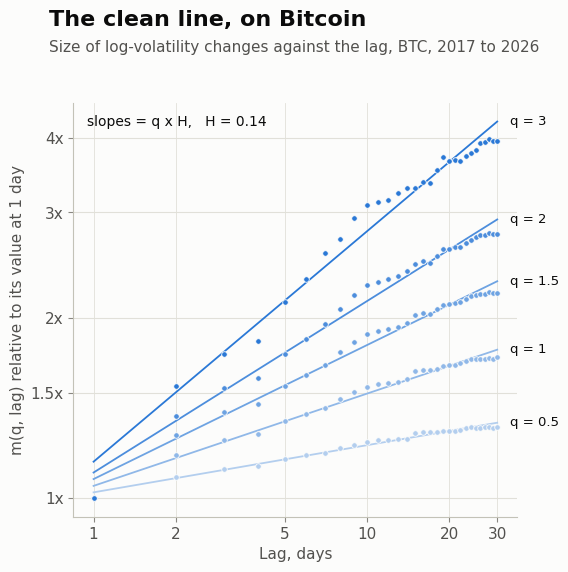

In [3]:
H_btc = rg.hurst(x, LAGS, QS)
fig = jp.scaling_fan(
    LAGS, {q: rg.structure_function(x, LAGS, q) for q in QS},
    title="The clean line, on Bitcoin",
    subtitle="Size of log-volatility changes against the lag, BTC, 2017 to 2026",
    xlabel="Lag, days", ylabel="m(q, lag) relative to its value at 1 day",
    note=f"slopes = q x H,   H = {H_btc:.2f}",
)
jp.save(fig, "06_scaling");

There it is. Five straight lines fanning out from one point, $R^2$ of 0.97 to 0.98, slopes proportional to $q$, and $H = 0.14$. The same number as the S&P 500 in the original paper.

A random walk in log-volatility would give a variance ratio of 4 between a 4-day and a 1-day change. Bitcoin gives 1.6. Volatility changes a great deal from one day to the next and not much more from one week to the next.

And the first measurement effect has already shown up. Without the weekend adjustment the estimate is 0.11 and the fit drops to an $R^2$ of about 0.75. A Saturday that runs at half the weekday volatility, every week, is not roughness. It is a calendar.

## 3. The sceptics' point: you never see volatility

The regression is run on realized volatility, an estimate. A realized variance built from $n$ returns equals the true variance of the day times a random factor, roughly a chi-squared with $n$ degrees of freedom divided by $n$. In logs,

$$\log \widehat\sigma_t = \log \sigma_t + \varepsilon_t, \qquad \operatorname{Var}(\varepsilon_t) \approx \tfrac14\,\psi'\!\Big(\frac{n}{2\kappa_t}\Big) \approx \frac{\kappa_t}{2n},$$

where $\psi'$ is the trigamma function and $\kappa_t \ge 1$ is the ratio of integrated quarticity to squared integrated variance, which is one when volatility is flat inside the day and larger when it moves. The errors of different days are independent.

Independent errors do to a path exactly what roughness does. They add the same amount, $2\operatorname{Var}(\varepsilon)$, to the variance of a change at every lag:

$$m(2, \Delta)_{\text{measured}} = m(2, \Delta)_{\text{true}} + 2\operatorname{Var}(\varepsilon).$$

A constant added to a rising curve flattens it on a log-log plot, and a flatter line is a smaller $H$. This is the argument of Cont and Das: realized volatility can look rough when volatility is not.

The argument makes a prediction that can be checked. The noisier the measurement, the rougher the result. So build each day's volatility from fewer and fewer returns.

In [4]:
STEPS = {"1m": 1, "5m": 5, "15m": 15, "30m": 30, "1h": 60, "2h": 120, "4h": 240}

def ladder(symbol):
    """H from the second moment for each intraday sampling, as measured and with the estimation error removed."""
    kappa = rg.daily_measures(grid[symbol], 1)["kappa"]     # measured once, on 1-minute returns
    rows = {}
    for label, step in STEPS.items():
        n = 1440 // step
        v = daily_log_vol(symbol, step)
        noise = float(np.mean(rg.noise_variance(n, np.minimum(kappa, n / 4.0))))
        raw, corrected = rg.hurst_noise_corrected(v, LAGS, noise)
        rows[label] = {"Returns per day": n, "H as measured": raw,
                       "Error share of the 1-day variance (%)": 100 * 2 * noise / rg.structure_function(v, LAGS, 2.0)[0],
                       "H, error removed": corrected}
    return pd.DataFrame(rows).T

ladders = {s[:3]: ladder(s) for s in grid}
kappa_btc = float(rg.daily_measures(grid["BTCUSDT"], 1)["kappa"].median())
print(f"Median kappa of a BTC day, from 1-minute returns: {kappa_btc:.2f}")
pd.concat(ladders, axis=1).round(3)

Median kappa of a BTC day, from 1-minute returns: 2.47


BTC                                                                                  ETH                                                      \
    Returns per day H as measured Error share of the 1-day variance (%) H, error removed Returns per day H as measured Error share of the 1-day variance (%)   
1m           1440.0         0.157                                 2.784            0.159          1440.0         0.150                                 2.759   
5m            288.0         0.143                                11.499            0.153           288.0         0.140                                11.632   
15m            96.0         0.130                                28.807            0.157            96.0         0.130                                28.875   
30m            48.0         0.116                                44.954            0.162            48.0         0.116                                45.203   
1h             24.0         0.099                                63.728            0.178            24.0         0.101                                66.567   
2h             12.0         0.083                                80.345            0.207            12.0         0.084                                84.500   
4h              6.0         0.062                                72.047            0.146             6.0         0.066                                76.953   

                      
    H, error removed  
1m             0.153  
5m             0.150  
15m            0.156  
30m            0.161  
1h             0.185  
2h             0.224  
4h             0.167

The prediction holds. As measured, $H$ for BTC falls steadily from 0.16 with 1-minute returns to 0.06 with 4-hour returns, and ETH does the same. With hourly returns two thirds of the variance of a one-day change in log-volatility is estimation error. The roughness you report is partly a property of your sampling frequency. On that, the sceptics are right.

The last column is the other half. The error variance is not a free parameter. It is known from the number of returns and from $\kappa$, so it can be subtracted before fitting. If the error explained the roughness, the corrected estimate would climb towards 0.5. It does not. It sits at 0.15 to 0.16 for every sampling from 1 minute to 30 minutes, where the correction is small and well determined, and drifts to 0.18 and 0.21 at 1 and 2 hours, where the correction is most of the signal and its own uncertainty takes over.

## 4. A placebo: a volatility that is smooth by construction

To see what the correction is worth, run the whole procedure on two simulated worlds where the answer is known.

- **Smooth.** Daily log-volatility is a Brownian-driven, mean-reverting process: true $H = 0.5$. Half-life 20 days, chosen by hand; dispersion of the level matched to Bitcoin's.
- **Rough.** Daily log-volatility is a fractional Brownian motion with $H = 0.1$, simulated exactly by Cholesky factorisation, with the size of a one-day change matched to Bitcoin's.

Each is then "measured" with $n$ returns per day and Bitcoin's median $\kappa$, exactly as the data are.

In [5]:
N_DAYS = len(grid["BTCUSDT"])
level_sd = float(np.nanstd(x))
change_sd = float(np.sqrt(rg.structure_function(daily_log_vol("BTCUSDT", 1), LAGS, 2.0)[0]))
truth = {"Smooth world (true H = 0.5)": rg.simulate_log_volatility("smooth", N_DAYS, level_sd=level_sd, half_life=20.0, seed=11),
         "Rough world (true H = 0.1)": rg.simulate_log_volatility("rough", N_DAYS, daily_change_sd=change_sd, seed=11)}

placebo = {}
for name, path in truth.items():
    rows = {"observed without error": {"H as measured": rg.hurst_noise_corrected(path, LAGS, 0.0)[0], "H, error removed": np.nan}}
    for label, step in STEPS.items():
        n = 1440 // step
        k = min(kappa_btc, n / 4.0)
        measured = rg.measured_log_volatility(path, n, kappa=k, seed=5)
        raw, corrected = rg.hurst_noise_corrected(measured, LAGS, float(rg.noise_variance(n, k)))
        rows[label] = {"H as measured": raw, "H, error removed": corrected}
    placebo[name] = pd.DataFrame(rows).T
pd.concat(placebo, axis=1).round(3)

Smooth world (true H = 0.5)                  Rough world (true H = 0.1)                 
                                     H as measured H, error removed              H as measured H, error removed
observed without error                       0.450              NaN                      0.113              NaN
1m                                           0.444            0.452                      0.113            0.114
5m                                           0.415            0.449                      0.107            0.113
15m                                          0.364            0.445                      0.095            0.111
30m                                          0.309            0.435                      0.085            0.114
1h                                           0.245            0.449                      0.066            0.114
2h                                           0.162            0.479                      0.039            0.111
4h                                           0.140            0.474                      0.033            0.111

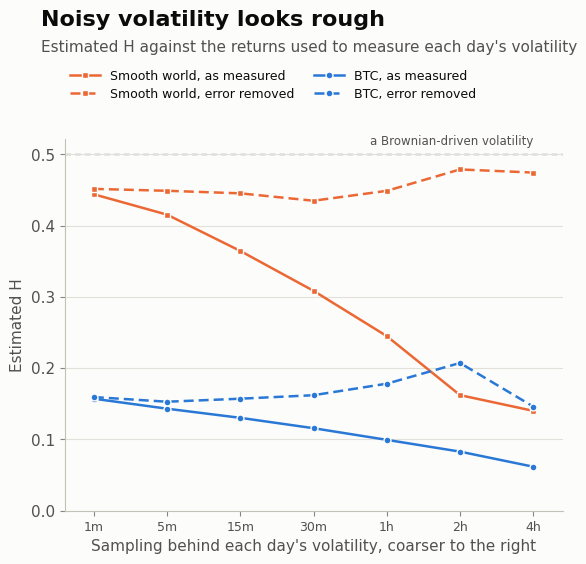

In [6]:
labels = list(STEPS)
smooth, btc = placebo["Smooth world (true H = 0.5)"].loc[labels], ladders["BTC"]
fig = jp.signature_plot(
    [{"name": "Smooth world, as measured", "y": smooth["H as measured"], "color": jp.ORANGE, "marker": "s"},
     {"name": "Smooth world, error removed", "y": smooth["H, error removed"], "color": jp.ORANGE, "marker": "s", "ls": (0, (4, 2))},
     {"name": "BTC, as measured", "y": btc["H as measured"], "color": jp.BLUE},
     {"name": "BTC, error removed", "y": btc["H, error removed"], "color": jp.BLUE, "ls": (0, (4, 2))}],
    labels,
    title="Noisy volatility looks rough",
    subtitle="Estimated H against the returns used to measure each day's volatility",
    ylabel="Estimated H", xlabel="Sampling behind each day's volatility, coarser to the right",
    reference=0.5, reference_label="a Brownian-driven volatility", log=False, ymin=0, legend=True,
)
jp.save(fig, "06_measurement");

The smooth world shows what Cont and Das describe. Observed without error it gives 0.45, a little under 0.5 because it mean-reverts. Measured with 5-minute returns it gives 0.42. With hourly returns, 0.25. With 4-hour returns, 0.14: a Brownian-driven volatility that reads as rough as Bitcoin.

Then the correction puts it back. With the estimation error removed the smooth world returns 0.44 to 0.48 at every sampling frequency, and the rough world returns its own 0.11.

Bitcoin behaves like the rough world. Its corrected estimate does not move towards 0.5; it stays where the best measurement had put it. The difference between the two orange lines is the artefact. The gap between the dashed orange line and the dashed blue line is not.

## 5. Down to one hour

The original paper claims the scaling holds "at any reasonable time scale". Nine years of 1-minute bars allow a test across almost three decades of lags: realized volatility of each hour from its sixty 1-minute returns, the intraweek rhythm of post 2 removed by subtracting the mean log-volatility of each hour of the week, and lags from one hour to thirty days. With sixty returns per window the estimation error is larger than in a daily measure, so it is removed in the same way.

80,175 hourly windows. Estimation error: 15% of the variance of a 1-hour change.
H over 1 hour to 30 days: 0.081 as measured, 0.088 with the error removed
H with the error removed, 1 to 24 hours: 0.109;  1 to 30 days: 0.087


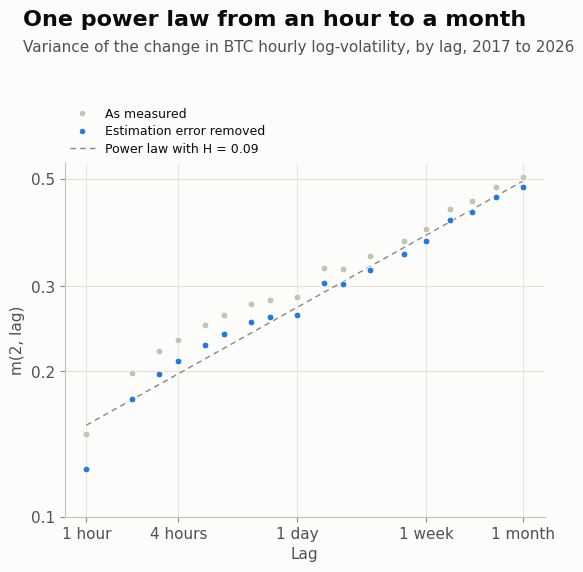

In [7]:
hourly = rg.hourly_measures(close["BTCUSDT"])
xh = rg.log_volatility(hourly["rv"], "h")
ny = xh.index.tz_convert("America/New_York")
xh = rg.remove_periodic_mean(xh, ny.dayofweek * 24 + ny.hour, BREAKS)
noise_h = float(np.nanmean(rg.noise_variance(60, np.clip(hourly["kappa"], 1, 15))))

HOURS = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 36, 48, 72, 120, 168, 240, 336, 480, 720])
m_measured = rg.structure_function(xh, HOURS, 2.0)
m_clean = m_measured - 2 * noise_h
slope, intercept = np.polyfit(np.log(HOURS), np.log(m_clean), 1)
short = HOURS <= 24
print(f"{int(hourly['rv'].notna().sum()):,} hourly windows. Estimation error: {100 * 2 * noise_h / m_measured[0]:.0f}% of the variance of a 1-hour change.")
print(f"H over 1 hour to 30 days: {rg.hurst_noise_corrected(xh, HOURS, noise_h)[0]:.3f} as measured, {slope / 2:.3f} with the error removed")
print(f"H with the error removed, 1 to 24 hours: {rg.hurst_noise_corrected(xh, HOURS[short], noise_h)[1]:.3f};  "
      f"1 to 30 days: {rg.hurst_noise_corrected(xh, HOURS[~short | (HOURS == 24)], noise_h)[1]:.3f}")

fig = jp.tail_plot(
    [{"name": "As measured", "x": HOURS, "y": m_measured, "color": jp.AXIS, "ls": "none", "marker": "o", "ms": 5},
     {"name": "Estimation error removed", "x": HOURS, "y": m_clean, "color": jp.BLUE, "ls": "none", "marker": "o", "ms": 5}],
    title="One power law from an hour to a month",
    subtitle="Variance of the change in BTC hourly log-volatility, by lag, 2017 to 2026",
    xlabel="Lag", ylabel="m(2, lag)",
    guides=[{"slope": slope, "x0": 1.0, "y0": float(np.exp(intercept)), "x1": 720.0,
             "text": f"Power law with H = {slope / 2:.2f}"}],
    xticks=[1, 4, 24, 168, 720], xticklabels=["1 hour", "4 hours", "1 day", "1 week", "1 month"],
    yticks=[0.1, 0.2, 0.3, 0.5],
)
jp.save(fig, "06_hour_to_month");

One line fits from an hour to a month, with $H = 0.09$. Volatility an hour apart differs almost as much as volatility a day apart: the variance of the change goes from 0.13 at one hour to 0.26 at one day and 0.49 at thirty days. For a Brownian-driven volatility it would go up twenty-four-fold between an hour and a day. Here it doubles.

The hourly estimate is lower than the daily 0.14, and the original paper explains why: a daily realized variance is an average over the day, and averaging smooths. Their estimates from intraday volatility proxies are also lower than those from daily realized variance.

The fit is not perfect. The one-hour point sits below the line and the curve is slightly concave.

## 6. What the regression cannot say

It establishes a scaling law between one hour and one month. Three things it does not establish.

**That volatility is a fractional process.** The same scaling over this range can be produced by a Brownian-driven volatility with several components reverting at very different speeds, minutes, hours, days and weeks. "Rough" is the one-parameter description of a volatility with no characteristic time scale; whether the kernel is truly a power law is not something thirty lags can decide.

**What happens below an hour.** Roughness is a statement about the limit of short lags, and that limit is exactly where the measurement breaks down. Volatility over ten minutes has to be estimated from ten 1-minute returns, the error dominates, and the correction has nothing left to correct. Posts 1 to 4 found volatility bursts lasting a minute or two. A volatility that spikes for minutes and relaxes is what a rough path looks like from close up, and also what a fast mean-reverting factor looks like. The regression does not separate them.

**Anything about option prices.** These are estimates under the real-world measure, from the path of realized volatility. Whether the short end of the smile needs a rough model, and how that competes with jumps, is post 7.

## 7. Caveats

- **The correction assumes the estimation error is the only noise** and that its variance is what the chi-squared approximation says. It ignores microstructure noise, which post 3 showed is negligible for BTC at 1 to 5 minutes, and it treats $\kappa$, itself estimated from 1-minute returns, as known. Where the correction is large, at hourly sampling and beyond, treat the corrected number as indicative.
- **Jumps are in realized variance.** With a jump share near zero (post 3) that matters little here. Bipower variation in place of realized variance gives 0.145 instead of 0.137.
- **The weekly adjustment is estimated in-sample** on three sub-periods. Without it the daily estimate is 0.11 rather than 0.14.
- **The placebo parameters are chosen by hand.** A smooth world with a shorter half-life mean-reverts inside the 30-day window and reads below 0.45 even without error. The placebo shows the mechanism and the correction, not a calibrated alternative.
- **One exchange, two coins.** The estimates for ETH are within 0.01 of those for BTC.

## 8. Takeaways

1. The famous regression works on Bitcoin: $H = 0.14$ on daily realized volatility, the value reported for the S&P 500.
2. The estimate moves with the measurement. A weekend effect takes it to 0.11. Coarser intraday sampling takes it from 0.16 down to 0.06. A reported $H$ without its sampling scheme is not a number.
3. Estimation error can make a smooth volatility look rough, exactly as the sceptics say. A Brownian-driven simulation measured with 4-hour returns reads 0.14.
4. Removing the known error restores the smooth simulation to 0.45 and leaves Bitcoin near 0.15. The roughness is in the data.
5. The scaling holds from one hour to one month. Below an hour, where it would matter most, it cannot be measured with bars.

## Simulating a rough path

A practical note, since it comes up: nothing here needs more than NumPy. The rough placebo is a fractional Brownian motion drawn exactly from its covariance matrix by Cholesky factorisation, six lines in `jumps.roughness.fractional_brownian_motion`, which is fine for a few thousand points. Long intraday paths of a rough model call for the hybrid scheme of Bennedsen, Lunde and Pakkanen.

## Equation images for the post

In [8]:
jp.render_equation(r"m(q,\Delta)=\mathrm{mean}\ |\log\sigma_{t+\Delta}-\log\sigma_t|^{q}\ \propto\ \Delta^{qH}", "06_eq_scaling",
                   "The size of volatility changes against the lag. H = 0.5 is Brownian, H near 0.1 is rough.", fontsize=20)
jp.render_equation(r"V_t=V_0+\dfrac{1}{\Gamma(H+\frac{1}{2})}\int_0^t (t-s)^{H-\frac{1}{2}}\,[\,\lambda(\theta-V_s)\,ds+\lambda\nu\sqrt{V_s}\,dB_s\,]", "06_eq_rough_heston",
                   "Rough Heston: Heston's increments, weighted by a power-law kernel", fontsize=14)
jp.render_equation(r"\log\hat{\sigma}_t=\log\sigma_t+\varepsilon_t,\qquad \mathrm{Var}(\varepsilon_t)\approx\dfrac{\kappa_t}{2n}", "06_eq_error",
                   "Realized volatility is an estimate. Its error mimics roughness.", fontsize=22);

## References

- Gatheral, J., Jaisson, T. and Rosenbaum, M. (2018). Volatility is rough. *Quantitative Finance*, 18(6), 933-949. [arXiv:1410.3394](https://arxiv.org/abs/1410.3394)
- Cont, R. and Das, P. (2024). Rough volatility: fact or artefact? *Sankhya B*, 86(1), 191-223. [arXiv:2203.13820](https://arxiv.org/abs/2203.13820)
- El Euch, O. and Rosenbaum, M. (2019). The characteristic function of rough Heston models. *Mathematical Finance*, 29(1), 3-38. [arXiv:1609.02108](https://arxiv.org/abs/1609.02108)
- Bayer, C., Friz, P. and Gatheral, J. (2016). Pricing under rough volatility. *Quantitative Finance*, 16(6), 887-904. [doi:10.1080/14697688.2015.1099717](https://doi.org/10.1080/14697688.2015.1099717)
- Bennedsen, M., Lunde, A. and Pakkanen, M. S. (2017). Hybrid scheme for Brownian semistationary processes. *Finance and Stochastics*. [arXiv:1507.03004](https://arxiv.org/abs/1507.03004)

The scaling regression, its settings and the reported values of $H$ were checked against the arXiv text of the first paper, the argument about estimation error against the abstract of the second, and the rough Heston equation against the third.

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*